# Cloud radiative forcing with ACLOUD data

Clouds over snow and sea ice raise the broadband surface albedo: the cloud absorbs in the near infrared, where snow is dark, so the irradiance that reaches the surface is shifted towards visible wavelengths, where snow is bright. Stapf et al. (2020) showed with ACLOUD aircraft observations (Fram Strait, May–June 2017, Polar 5 and Polar 6) that the traditional shortwave cloud radiative forcing (CRF), which takes the clear-sky reference with the albedo observed under the cloud, underestimates the shortwave cooling by about a factor of two.

- Stapf, J., Ehrlich, A., Jäkel, E., Lüpkes, C., and Wendisch, M. (2020): Reassessment of shortwave surface cloud radiative forcing in the Arctic: consideration of surface-albedo–cloud interactions, *Atmos. Chem. Phys.*, 20, 9895–9914, [doi:10.5194/acp-20-9895-2020](https://doi.org/10.5194/acp-20-9895-2020).
- Data: Stapf et al. (2019), PANGAEA, [doi:10.1594/PANGAEA.909289](https://doi.org/10.1594/PANGAEA.909289).

Part 1 shows the albedo shift in a model-only experiment. Part 2 recomputes both CRF estimates of the paper from the published data with a pyRadtran clear-sky lookup table. The notebook needs `pangaeapy` and `pvlib` and downloads about 55 MB on the first run.

In [1]:
import logging
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pvlib
import requests
import xarray as xr
from pangaeapy import PanDataSet

import pyradtran  # registers the .pyradtran accessor
from pyradtran import Var

logging.getLogger("pyradtran").setLevel(logging.ERROR)
run = dict(save_to_file=False, show_progress=False)

## Part 1: the albedo shift in the model

The surface is the libRadtran IGBP spectral albedo of fresh snow (`albedo_library IGBP`, `brdf_rpv_type 19`) under the subarctic-summer atmosphere `afglss`. A liquid cloud between 0.3 and 1.0 km (10 µm effective radius, LWC = LWP / 700 m) is added for LWP up to 150 g m⁻². The broadband albedo is $\alpha = E^\uparrow / (E_\mathrm{dir} + E^\downarrow_\mathrm{diff})$ from the broadband config of {doc}`arctic_cloud_experiment`, with the atmosphere switched by a dotted config key.

The IGBP parameterisation itself depends on the illumination: for clear sky it uses the actual solar zenith angle (SZA), under a cloud libRadtran evaluates it at 53°, standing in for diffuse light. Part of the clear-to-cloudy difference at SZA ≠ 53° comes from that switch; the rest is the spectral shift of the irradiance.

In [2]:
lwps = np.array([0, 10, 50, 100, 150.0])  # g m-2, 0 = clear sky
cbh, cth = 0.3, 1.0                       # km
lwc = np.where(lwps > 0, lwps / ((cth - cbh) * 1000), np.nan)  # g m-3

ds = xr.Dataset(
    coords={
        "time": [pd.Timestamp("2017-06-05 12:00")],
        "latitude": ("time", [80.0]),
        "longitude": ("time", [10.0]),
        "sza": [50.0, 60.0, 70.0, 80.0],
        "lwp": lwps,
    },
    data_vars={
        "lwc": ("lwp", lwc),
        "reff": ("lwp", np.full(lwps.size, 10.0)),
        "cbh": ("lwp", np.full(lwps.size, cbh)),
        "cth": ("lwp", np.full(lwps.size, cth)),
    },
)
ds["sza_deg"] = ds.sza
cloud = dict(cloud_wc_var="lwc", cloud_reff_var="reff", cloud_top_var="cth", cloud_bottom_var="cbh")
snow = {"sza": Var("sza_deg"), "albedo_library": "IGBP", "brdf_rpv_type": 19}

bb = ds.pyradtran.run(
    config_path="config/arctic_cloud_experiment_solar.yaml",
    params={**snow, "paths.atmosphere_profile": "afglss"},
    **cloud, **run,
).isel(time=0, altitude=0)
albedo_bb = bb.eup / (bb.edir + bb.edn)
albedo_bb.round(3).to_pandas()

sza,50.0,60.0,70.0,80.0
lwp,,,,
0.0,0.847,0.870,0.887,0.898
10.0,0.870,0.873,0.876,0.881
50.0,0.901,0.903,0.904,0.907
100.0,0.919,0.919,0.920,0.922
150.0,0.928,0.929,0.929,0.931


The spectral run (`config/arctic_cloud_experiment_solar_spectral.yaml`, 300–2500 nm) shows why: at SZA 60° a cloud of 100 g m⁻² removes most of the near-infrared irradiance, where the snow albedo is low.

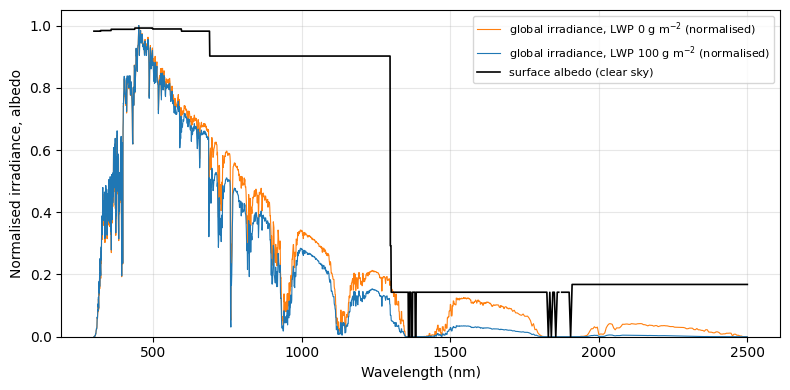

In [3]:
spec = ds.sel(sza=[60.0], lwp=[0.0, 100.0]).pyradtran.run(
    config_path="config/arctic_cloud_experiment_solar_spectral.yaml",
    params=snow, **cloud, **run,
).isel(time=0, altitude=0, sza=0)
eglo = spec.edir + spec.edn

fig, ax = plt.subplots(figsize=(8, 4))
for lwp, color in [(0.0, "C1"), (100.0, "C0")]:
    e = eglo.sel(lwp=lwp)
    ax.plot(spec.wavelength, e / e.max(), color=color, lw=0.8,
            label=f"global irradiance, LWP {lwp:.0f} g m$^{{-2}}$ (normalised)")
ax.plot(spec.wavelength, (spec.eup / eglo).sel(lwp=0.0), "k", lw=1.2, label="surface albedo (clear sky)")
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Normalised irradiance, albedo")
ax.set_ylim(0, 1.05)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()

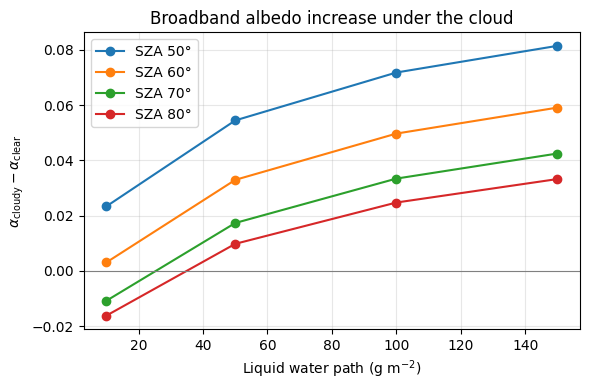

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
d_albedo = albedo_bb - albedo_bb.sel(lwp=0)
for sza in d_albedo.sza.values:
    ax.plot(d_albedo.lwp[1:], d_albedo.sel(sza=sza)[1:], "o-", label=f"SZA {sza:.0f}°")
ax.axhline(0, color="0.5", lw=0.8)
ax.set_xlabel("Liquid water path (g m$^{-2}$)")
ax.set_ylabel(r"$\alpha_\mathrm{cloudy} - \alpha_\mathrm{clear}$")
ax.set_title("Broadband albedo increase under the cloud")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()

The broadband albedo rises with LWP at every SZA: at 60° from 0.870 in clear sky to 0.903 under 50 g m⁻² and 0.929 under 150 g m⁻². Under the cloud the albedo hardly depends on the SZA any more, because the surface sees diffuse light. At 80° the clear-sky albedo (0.898) is already high and the increase is smaller; under a thin cloud (10 g m⁻²) at SZA ≥ 70° the albedo even drops slightly, because libRadtran then evaluates the IGBP albedo at 53° instead of the actual SZA. The ACLOUD retrievals below show a mean increase of 0.06.

## Part 2: ACLOUD observations

### Data

The PANGAEA file holds, for the Polar 5 and Polar 6 low-level flight legs, the observed albedo $\alpha_\mathrm{all}$, the retrieved cloud-free albedo $\alpha_\mathrm{cf}$, the retrieved LWP, the sea-ice fraction, the simulated cloud-free downward irradiance $F^\downarrow_\mathrm{cf}$ and the paper's CRF values. `pangaeapy` provides the download URL; the file is cached in `data/`. As in the paper, only points over closed sea ice (> 98 %) under a liquid cloud (LWP > 1 g m⁻²) are kept.

In [5]:
PANGAEA_ID = 909289
cache = Path(f"data/pangaea_{PANGAEA_ID}.nc")
if not cache.exists():
    meta = PanDataSet(PANGAEA_ID).metaxml
    url = re.search(r'key="staticURL"\s+value="([^"]+)"', meta).group(1)
    cache.parent.mkdir(exist_ok=True)
    cache.write_bytes(requests.get(url, timeout=600).content)

raw = xr.concat([xr.open_dataset(cache, group=g) for g in ("P5", "P6")], dim="Time")
keep = (raw.I_f > 98) & (raw.LWP > 1) & np.isfinite(raw.Obs_alb) & np.isfinite(raw.Ret_cf_alb)
obs = raw.where(keep.compute(), drop=True).load()

sun = pvlib.solarposition.get_solarposition(pd.DatetimeIndex(obs.time.values), obs.Lat.values, obs.Lon.values)
obs["SZA"] = ("Time", sun["zenith"].values)

print(f"{obs.sizes['Time']:,} of {raw.sizes['Time']:,} points kept")
for name in ["Obs_alb", "Ret_cf_alb", "LWP", "SZA", "SW_F_dw_simu"]:
    print(f"{name:13s} mean {float(obs[name].mean()):7.2f}  range {float(obs[name].min()):7.2f} – {float(obs[name].max()):7.2f}")

~/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


230,353 of 978,763 points kept
Obs_alb       mean    0.81  range    0.53 –    0.97
Ret_cf_alb    mean    0.75  range    0.52 –    0.90
LWP           mean   58.39  range    1.00 –  286.38
SZA           mean   61.03  range   56.23 –   68.64
SW_F_dw_simu  mean  516.68  range  382.13 –  614.92


### Method

Following Stapf et al. (2020, Eq. 9), the shortwave CRF is the observed cloudy net irradiance minus the clear-sky net irradiance over a surface with albedo $\alpha$,

$$\Delta F_\mathrm{sw}(\alpha) = F_\mathrm{net}^\mathrm{cloudy} - F^\downarrow_\mathrm{cf}(\mathrm{SZA}, \alpha)\,(1 - \alpha),$$

evaluated once with $\alpha_\mathrm{all}$ (traditional) and once with $\alpha_\mathrm{cf}$ (corrected).

The cloudy net irradiance is not in the file, but the published CRF fixes it: $F_\mathrm{net}^\mathrm{cloudy} = \Delta F_\mathrm{sw}(\alpha_\mathrm{all}) + F^\downarrow_\mathrm{cf}(1 - \alpha_\mathrm{all})$, with the paper's $F^\downarrow_\mathrm{cf}$. The clear-sky term is then replaced by a pyRadtran lookup table over SZA × albedo, so the two CRF values below are independent recalculations that share only the observed cloudy net irradiance with the paper.

An earlier version of this notebook built the "observed" net irradiance from the clear-sky table itself. The traditional CRF was then zero by construction and the corrected one only the albedo term.

In [6]:
f_net_cloudy = obs.CRF_SW_obs + obs.SW_F_dw_simu * (1 - obs.Obs_alb)  # W m-2

lut_ds = xr.Dataset(
    coords={
        "time": [pd.Timestamp("2017-06-05 12:00")],
        "latitude": ("time", [80.0]),
        "longitude": ("time", [10.0]),
        "sza": np.arange(50, 72.6, 2.5),
        "albedo": np.round(np.arange(0.45, 1.001, 0.05), 2),
    }
)
lut_ds["sza_deg"] = lut_ds.sza
lut_ds["albedo_value"] = lut_ds.albedo

points = {"sza": xr.DataArray(obs.SZA.values, dims="Time")}
a_all = xr.DataArray(obs.Obs_alb.values, dims="Time")
a_cf = xr.DataArray(obs.Ret_cf_alb.values, dims="Time")

rows, crf = [], {}
for atmosphere in ["afglss", "afglsw"]:
    lut = lut_ds.pyradtran.run(
        config_path="config/arctic_cloud_experiment_solar.yaml",
        params={"sza": Var("sza_deg"), "albedo": Var("albedo_value"),
                "paths.atmosphere_profile": atmosphere},
        **run,
    ).isel(time=0, altitude=0)
    f_dn = (lut.edir + lut.edn) / 1e3        # mW m-2 -> W m-2
    f_net = f_dn - lut.eup / 1e3
    trad = f_net_cloudy.values - f_net.interp(albedo=a_all, **points).values
    corr = f_net_cloudy.values - f_net.interp(albedo=a_cf, **points).values
    crf[atmosphere] = (trad, corr)
    rows.append({
        "clear-sky model": f"pyRadtran {atmosphere}",
        "F_dn clear (W m-2)": float(f_dn.interp(albedo=a_all, **points).mean()),
        "CRF_sw(alpha_all)": np.mean(trad),
        "CRF_sw(alpha_cf)": np.mean(corr),
    })
rows.append({
    "clear-sky model": "Stapf et al. (published)",
    "F_dn clear (W m-2)": float(obs.SW_F_dw_simu.mean()),
    "CRF_sw(alpha_all)": float(obs.CRF_SW_obs.mean()),
    "CRF_sw(alpha_cf)": float(obs.CRF_SW_cf.mean()),
})
pd.DataFrame(rows).set_index("clear-sky model").round(1)

,F_dn clear (W m-2),CRF_sw(alpha_all),CRF_sw(alpha_cf)
clear-sky model,,,
pyRadtran afglss,490.6,-27.0,-55.4
pyRadtran afglsw,527.4,-34.2,-64.7
Stapf et al. (published),516.7,-31.9,-62.3


The recalculation reproduces the paper. Over closed sea ice the traditional estimate gives a shortwave CRF of −27 to −34 W m⁻², the corrected estimate −55 to −65 W m⁻², against −32 and −62 W m⁻² published. The correction roughly doubles the shortwave cooling.

The remaining differences come from the clear-sky downward irradiance. The two standard atmospheres bracket the paper's value (491 and 527 against 517 W m⁻²) because they bracket the water vapour: subarctic summer is moister and subarctic winter drier than the atmosphere of the paper's simulations. The earlier figures of this notebook (+0.01 and −28.8 W m⁻²) were the result of the bug described above, not of the atmosphere.

net CRF, afglss: +41.8 W m-2 (alpha_all), +13.5 W m-2 (alpha_cf)
net CRF, published: +36.9 W m-2 (alpha_all), +6.5 W m-2 (alpha_cf)


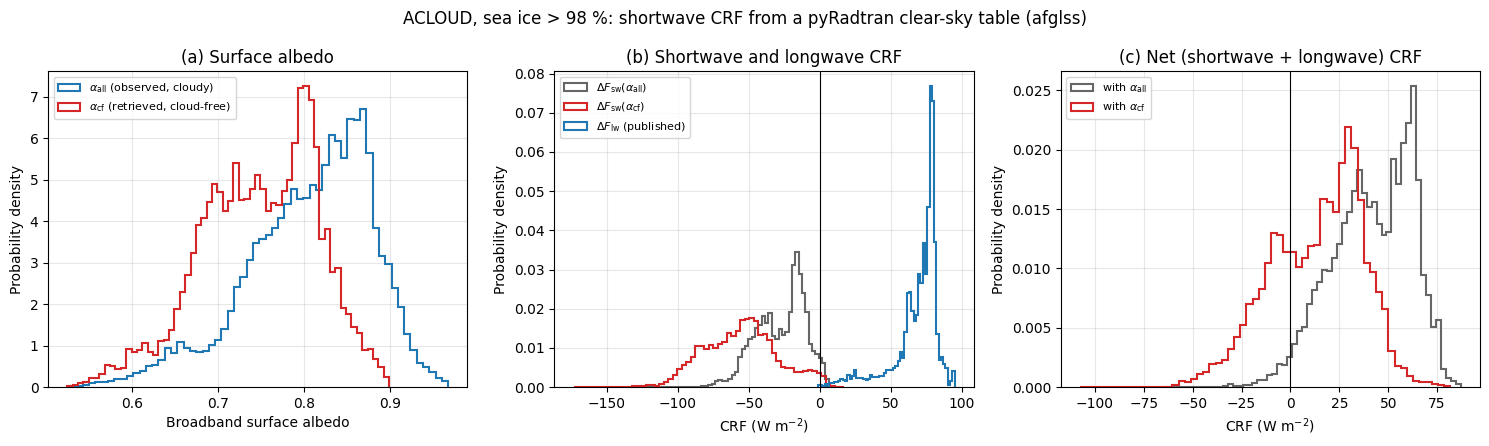

In [7]:
trad, corr = crf["afglss"]
lw = obs.CRF_LW.values
kw = dict(bins=60, density=True, histtype="step", lw=1.5)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

ax = axes[0]
ax.hist(obs.Obs_alb, color="C0", label=r"$\alpha_\mathrm{all}$ (observed, cloudy)", **kw)
ax.hist(obs.Ret_cf_alb, color="C3", label=r"$\alpha_\mathrm{cf}$ (retrieved, cloud-free)", **kw)
ax.set_xlabel("Broadband surface albedo")
ax.set_title("(a) Surface albedo")

ax = axes[1]
ax.hist(trad, color="0.4", label=r"$\Delta F_\mathrm{sw}(\alpha_\mathrm{all})$", **kw)
ax.hist(corr, color="C3", label=r"$\Delta F_\mathrm{sw}(\alpha_\mathrm{cf})$", **kw)
ax.hist(lw, color="C0", label=r"$\Delta F_\mathrm{lw}$ (published)", **kw)
ax.set_xlabel("CRF (W m$^{-2}$)")
ax.set_title("(b) Shortwave and longwave CRF")

ax = axes[2]
ax.hist(trad + lw, color="0.4", label=r"with $\alpha_\mathrm{all}$", **kw)
ax.hist(corr + lw, color="C3", label=r"with $\alpha_\mathrm{cf}$", **kw)
ax.set_xlabel("CRF (W m$^{-2}$)")
ax.set_title("(c) Net (shortwave + longwave) CRF")

for ax in axes:
    ax.set_ylabel("Probability density")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
for ax in axes[1:]:
    ax.axvline(0, color="k", lw=0.8)
fig.suptitle("ACLOUD, sea ice > 98 %: shortwave CRF from a pyRadtran clear-sky table (afglss)")
fig.tight_layout()

print(f"net CRF, afglss: {np.mean(trad + lw):+.1f} W m-2 (alpha_all), {np.mean(corr + lw):+.1f} W m-2 (alpha_cf)")
print(f"net CRF, published: {float((obs.CRF_SW_obs + obs.CRF_LW).mean()):+.1f} W m-2 (alpha_all), "
      f"{float((obs.CRF_SW_cf + obs.CRF_LW).mean()):+.1f} W m-2 (alpha_cf)")

With the published longwave CRF (+69 W m⁻²) the net effect of the clouds on the surface stays positive. With the subarctic-summer table it is +42 W m⁻² with the traditional and +14 W m⁻² with the corrected shortwave term, against +37 and +7 W m⁻² in the paper. Clouds over the closed sea ice warmed the surface during ACLOUD, but considerably less than the traditional estimate suggests.